In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
rng = np.random.default_rng(42)

Task 1, boxplot of Flipkart prices loaded from a CSV

   product_id   price
0           1  1652.0
1           2   980.0
2           3  1875.0
3           4  1970.0
4           5   524.0


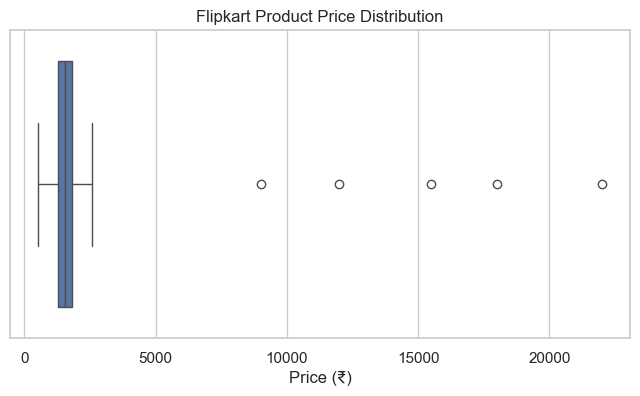

In [2]:
prices = np.concatenate([rng.normal(1500, 500, 95).clip(200, None), [9000, 12000, 15500, 18000, 22000]])
pd.DataFrame({'product_id': range(1, 101), 'price': prices.round(0)}).to_csv('flipkart_prices.csv', index=False)

flipkart = pd.read_csv('flipkart_prices.csv')
print(flipkart.head())

plt.figure(figsize=(8, 4))
sns.boxplot(data=flipkart, x='price')
plt.xlabel('Price (₹)')
plt.title('Flipkart Product Price Distribution')
plt.show()

Task 2, violin plot of Zomato order amounts

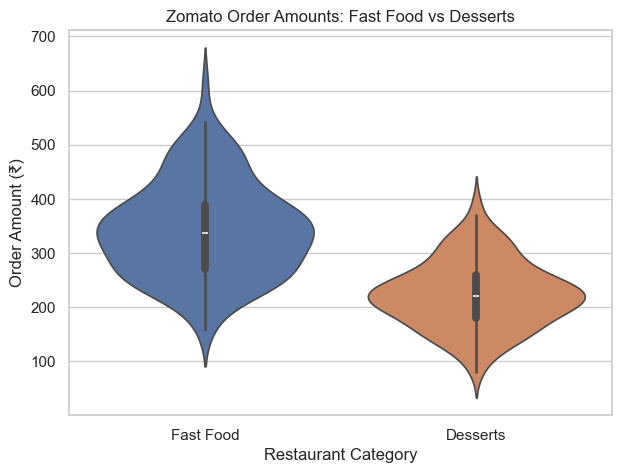

In [3]:
zomato = pd.DataFrame({
    'category': ['Fast Food'] * 120 + ['Desserts'] * 120,
    'order_amount': np.concatenate([
        rng.normal(350, 90, 120).clip(100, None),
        rng.normal(220, 60, 120).clip(80, None),
    ]).round(0)
})

plt.figure(figsize=(7, 5))
sns.violinplot(data=zomato, x='category', y='order_amount', hue='category', legend=False)
plt.xlabel('Restaurant Category')
plt.ylabel('Order Amount (₹)')
plt.title('Zomato Order Amounts: Fast Food vs Desserts')
plt.show()

Task 3, IPL ticket prices boxplot and outliers

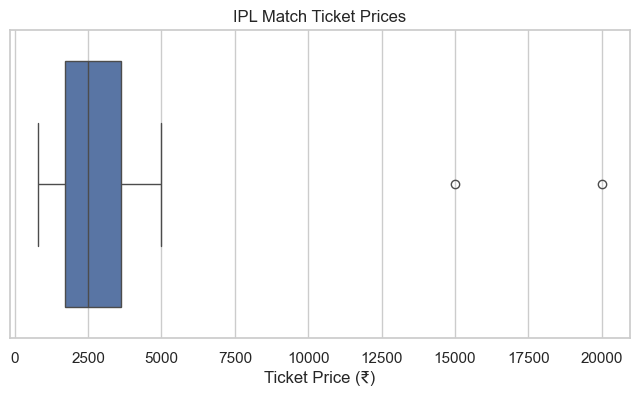

Q1=1725.0, Q3=3625.0, IQR=1900.0, whiskers limit: -1125.0 to 6475.0
Outliers: [15000 20000]


In [4]:
ticket_prices = np.array([800, 1000, 1200, 1500, 1500, 1800, 2000, 2000, 2200, 2500,
                          2500, 2800, 3000, 3000, 3500, 4000, 4500, 5000, 15000, 20000])

plt.figure(figsize=(8, 4))
sns.boxplot(x=ticket_prices)
plt.xlabel('Ticket Price (₹)')
plt.title('IPL Match Ticket Prices')
plt.show()

q1, q3 = np.percentile(ticket_prices, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = ticket_prices[(ticket_prices < lower) | (ticket_prices > upper)]
print(f'Q1={q1}, Q3={q3}, IQR={iqr}, whiskers limit: {lower} to {upper}')
print('Outliers:', outliers)

Task 4, violin plot of daily step counts

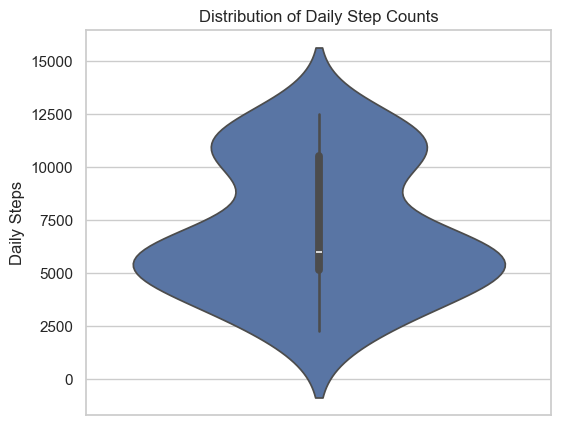

In [5]:
steps = np.concatenate([rng.normal(5000, 1200, 20), rng.normal(11000, 1500, 10)]).round().clip(1000, None)
steps_df = pd.DataFrame({'steps': steps})

plt.figure(figsize=(6, 5))
sns.violinplot(data=steps_df, y='steps')
plt.ylabel('Daily Steps')
plt.title('Distribution of Daily Step Counts')
plt.show()